# Analisando Grafos do SNAP: `email-EuAll`

Notebook de orquestração do trabalho prático de Teoria dos Grafos (IC/UFBA).

**Grafo atribuído:** matrícula 224216275, com S = 2+2+4+2+1+6+2+7+5 = 31 e U = 75, então
(31 × 76) mod 129 = 2356 mod 129 = **34**, o que dá **G34 = `email-EuAll`** (SNAP).

Toda a lógica está nos módulos de `src/`. O notebook só executa o pipeline e exibe as
tabelas (`results/tables/`) e as figuras (`results/figures/`).

* `RECOMPUTE = False`: apenas carrega e exibe os resultados já gerados (rápido).
* `RECOMPUTE = True`: refaz tudo do zero (~25 min), executando cada módulo como em
  `python -m src.<modulo>`. Requer os dados brutos (`python scripts/download_data.py`).

In [1]:
import os
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
pd.set_option("display.max_colwidth", 120)

RECOMPUTE = False


def run(module, *args):
    """Executa `python -m src.<module>` na raiz do projeto, se RECOMPUTE."""
    if not RECOMPUTE:
        return
    print(f"$ python -m src.{module}", *args)
    env = {**os.environ, "PYTHONIOENCODING": "utf-8"}  # saída com ∞, σ, γ no Windows
    r = subprocess.run([sys.executable, "-m", f"src.{module}", *args], cwd=ROOT, env=env,
                       capture_output=True, text=True, encoding="utf-8")
    print(r.stdout[-3000:])
    if r.returncode != 0:
        print(r.stderr[-3000:])
    r.check_returncode()


def table(name):
    return pd.read_csv(TABLES / name)


def figure(name, width=900):
    display(Image(filename=str(FIGURES / name), width=width))

## 1. Tratamento dos dados

Remoção de auto-loops, conversão de dirigido para não dirigido simples e extração da
maior componente conexa (LCC). O dataset não tem timestamps nem arestas múltiplas, então
não há etapa temporal nem de multigrafo.

In [2]:
run("treatment")
run("prepare_data")
table("tratamento_evolucao.csv")

,etapa,vertices,arestas
0,Grafo bruto (dirigido),265214,420045
1,Após remoção de auto-loops (dirigido),265214,418956
2,Após conversão para não dirigido simples,265214,364481
3,Maior componente conexa (LCC),224832,339925


## 2. Parte I: análise estrutural

In [3]:
run("metrics")
run("distances")
run("clustering")
run("visualize")
run("part1_summary")
table("parte1_resumo.csv")

,medida,grafo_completo,lcc,status,metodo
0,Número de vértices,265214,224832,Computado (exato),Contagem
1,Número de arestas,364481,339925,Computado (exato),Contagem (não dirigido simples)
2,Grau mínimo,0,1,Computado (exato),Lista de adjacência
3,Grau máximo,7636,7636,Computado (exato),Lista de adjacência
4,Grau médio,2.7486,3.0238,Computado (exato),2m/n
5,Distribuição de graus,-,ver figura,Computado (exato),distribuicao_graus.csv / distribuicao_graus.png
6,Densidade,1.036e-05,1.345e-05,Computado (exato),2m / (n(n-1))
7,Número de componentes conexas,15836,1,Computado (exato),BFS
8,Tamanho de cada componente,ver tabela,-,Computado (exato),componentes_tamanhos.csv / componentes_frequencia.csv
9,Diâmetro,∞ (desconexo),14,Computado (exato),"BoundingDiameters (Takes & Kosters, 2011), 4 BFS; no grafo completo é infinito por ser desconexo"


In [4]:
display(table("parte1_basicas.csv"))
display(table("parte1_diametro_raio.csv"))
display(table("parte1_caminhos_amostragem.csv"))
table("parte1_clusterizacao.csv")

,metrica,grafo_completo,lcc
0,vertices,265214.00000,224832.000000
1,arestas,364481.00000,339925.000000
2,grau_min,0.00000,1.000000
3,grau_max,7636.00000,7636.000000
4,grau_medio,2.74858,3.023813
5,densidade,0.00001,0.000013
6,componentes,15836.00000,1.000000
7,maior_componente,224832.00000,224832.000000
8,menor_componente,1.00000,224832.000000


,diametro_lo,diametro_up,raio_lo,raio_up,bfs,exato,tempo_s
0,14,14,7,7,4,True,0.650245


,k,L_medio,L_desvio,L_ic95_inf,L_ic95_sup,ecc_max_amostra,ecc_min_amostra,tempo_s
0,100,4.117795,0.412131,4.037017,4.198572,13,9,15.308287
1,500,4.127090,0.334097,4.097805,4.156375,13,8,76.213860


,escopo,triangulos,clusterizacao_media,transitividade,vertices_em_triangulos,tempo_s
0,grafo_completo,267313,0.067085,0.004106,25132,1.055725
1,lcc,267313,0.079134,0.004163,25132,0.817946


### Tamanho das componentes conexas (grafo completo)

,0,1,2,3,4,5,6,7,8,9,...,26,27,28,29,30,31,32,33,34,35
tamanho,1,2,3,4,5,6,7,8,9,10,...,35,38,40,43,45,62,86,1373,1850,224832
quantidade,205,13276,1426,403,172,100,53,40,32,25,...,1,1,1,1,1,1,1,1,1,1


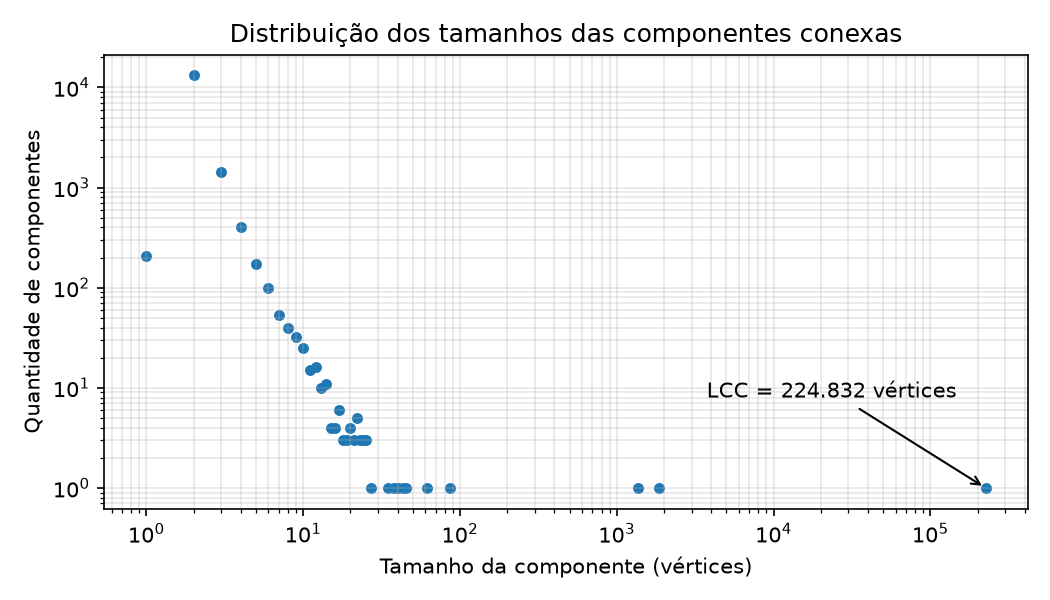

In [5]:
display(table("componentes_frequencia.csv").T)
figure("componentes_tamanhos.png", 700)

### Distribuição de graus e visualização (amostra de 300 vértices)

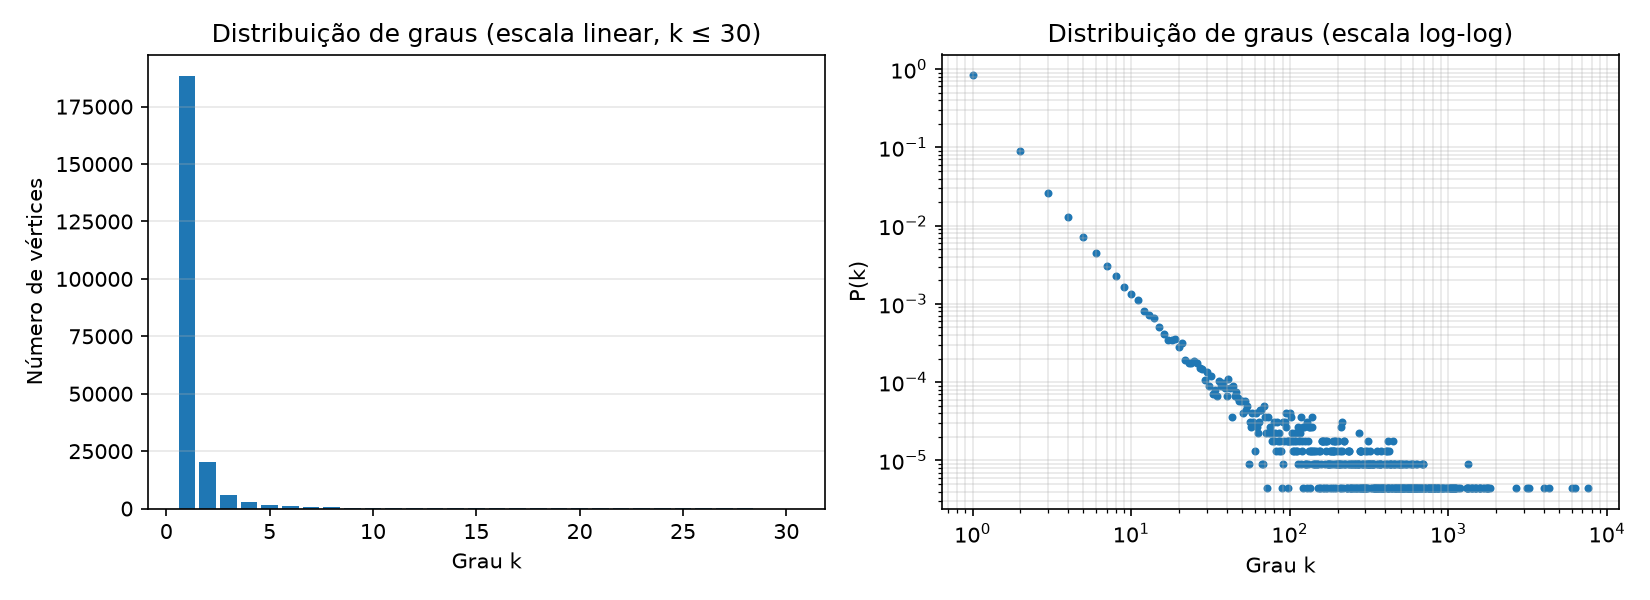

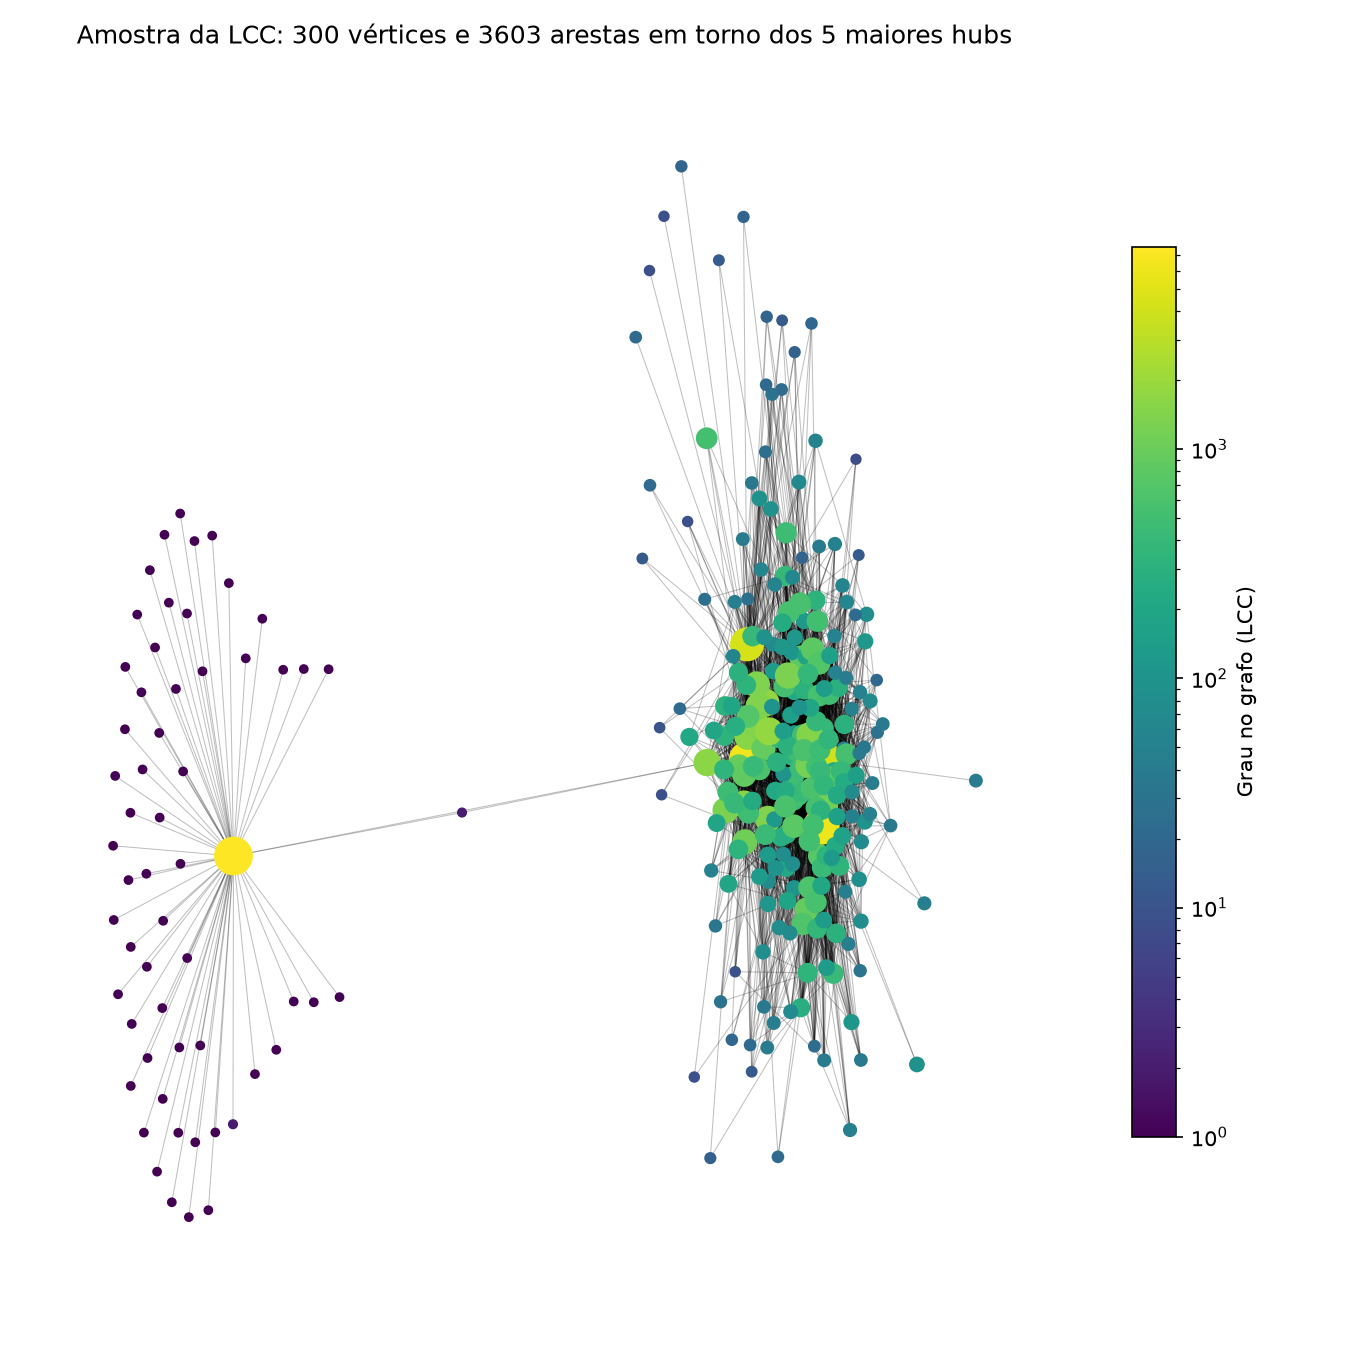

In [6]:
figure("distribuicao_graus.png")
figure("visualizacao_amostra.png", 650)

## 3. Parte II: algoritmos

Implementações próprias em `src/algorithms/`, conferidas com o NetworkX em `tests/`.
Tempos: 30 execuções (IC 95% Normal/Z) e 10 no Floyd-Warshall em Python puro
(IC 95% t-Student). Pesos sintéticos inteiros em [1, 10] (semente 42).

In [7]:
run("benchmark")
table("parte2_tempos.csv")

,algoritmo,grafo,V,E,complexidade,n,media_s,desvio_s,ic95_inf_s,ic95_sup_s,distribuicao,valor_critico
0,BFS,LCC,224832,339925,O(V+E),30,0.197989,0.042489,0.182785,0.213194,Normal (Z),1.960000
1,DFS (iterativa),LCC,224832,339925,O(V+E),30,0.319535,0.009261,0.316221,0.322848,Normal (Z),1.960000
2,Eulerianidade (não dirigido),LCC,224832,339925,O(V+E),30,0.165793,0.003129,0.164673,0.166912,Normal (Z),1.960000
3,Eulerianidade (dirigido),G_dir,265214,418956,O(V+E),30,0.505700,0.004958,0.503926,0.507474,Normal (Z),1.960000
4,Dijkstra (heap),LCC ponderada,224832,339925,O((V+E) log V),30,0.770336,0.010125,0.766713,0.773959,Normal (Z),1.960000
5,Bellman-Ford,subgrafo 300,300,372,O(V·E),30,0.000345,0.000013,0.000341,0.000350,Normal (Z),1.960000
6,Floyd-Warshall (Python puro),subgrafo 300,300,372,O(V³),10,1.952117,0.016986,1.939966,1.964268,t-Student,2.262157
7,Floyd-Warshall (numpy),subgrafo 300,300,372,O(V³),30,0.057031,0.001306,0.056563,0.057498,Normal (Z),1.960000
8,Tarjan (SCC),G_dir,265214,418956,O(V+E),30,0.607144,0.011355,0.603081,0.611208,Normal (Z),1.960000
9,Tarjan (pontes/articulações),LCC,224832,339925,O(V+E),30,0.577095,0.023626,0.568640,0.585549,Normal (Z),1.960000


In [8]:
table("parte2_resultados.csv")

,algoritmo,grafo,resultado
0,BFS,LCC,visitou 224832 vértices; profundidade máx. 10
1,DFS (iterativa),LCC,visitou 224832 vértices
2,Eulerianidade (não dirigido),LCC,não euleriano; 198520 vértices de grau ímpar
3,Eulerianidade (dirigido),G_dir,não euleriano; 242614 vértices com entrada≠saída; fracamente conexo=False
4,Dijkstra (heap),LCC ponderada,alcançou 224832 vértices; dist. máx. 41
5,Bellman-Ford,subgrafo 300,alcançou 300 vértices; 3 rodadas
6,Floyd-Warshall (Python puro),subgrafo 300,matriz 300×300; dist. máx. 20
7,Floyd-Warshall (numpy),subgrafo 300,matriz 300×300; dist. máx. 20
8,Tarjan (SCC),G_dir,231000 SCCs; maior com 34203 vértices
9,Tarjan (pontes/articulações),LCC,188668 pontes; 2223 articulações


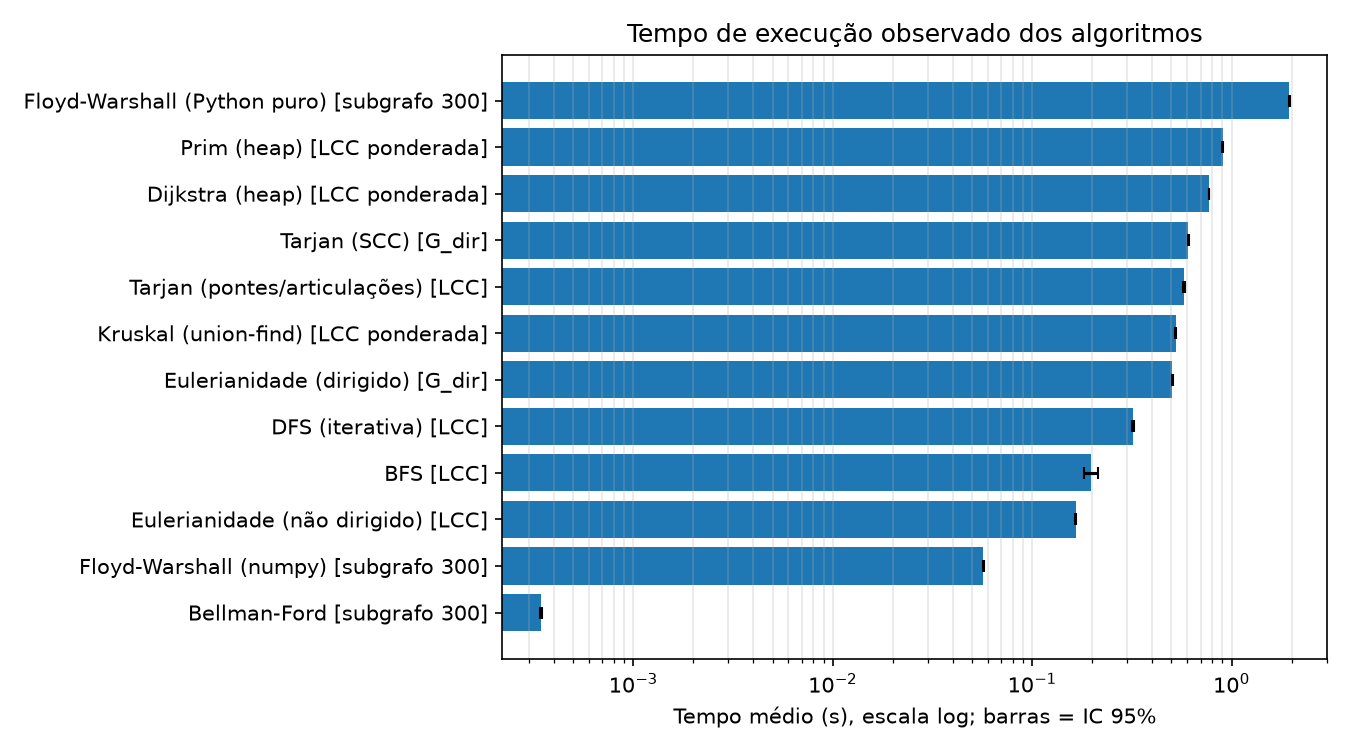

,algoritmo,expoente_observado,expoente_teorico
0,BFS,1.448666,1
1,Dijkstra,1.529263,1
2,Floyd-Warshall,2.982753,3


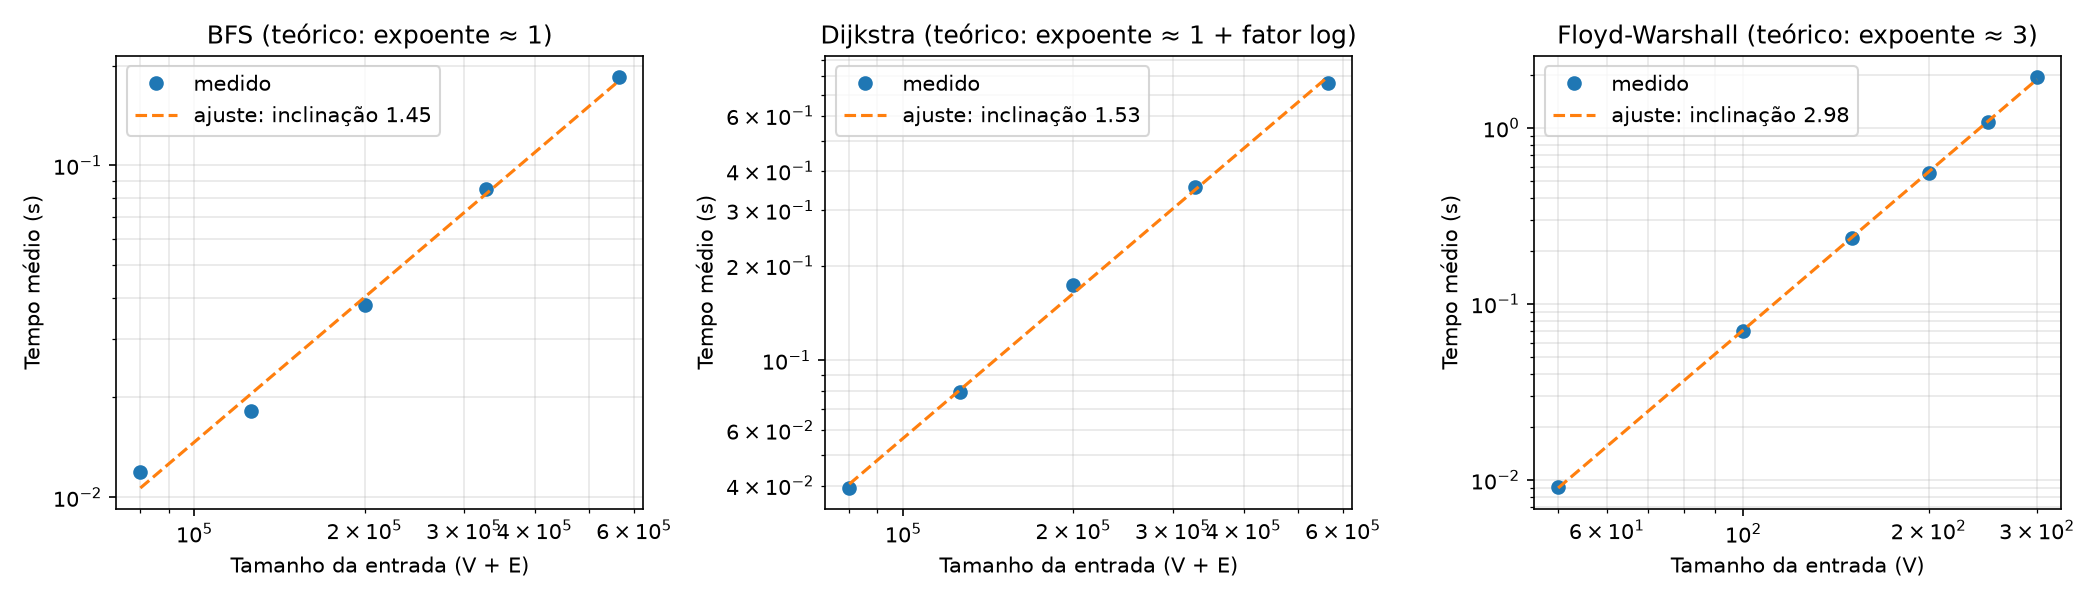

In [9]:
figure("tempos_algoritmos.png", 750)
display(table("parte2_expoentes.csv"))
figure("escala_algoritmos.png")

## 4. Parte III: propriedades da rede

### 4.1 Small-world

In [10]:
run("smallworld")
display(table("parte3_smallworld.csv"))
table("parte3_smallworld_er.csv")

,metrica,real,er_medido,er_analitico,razao_real_er
0,Comprimento médio L,4.127090,11.115621,11.136828,0.371287
1,Clusterização média C,0.079134,0.000008,0.000013,10141.945694
2,σ = (C/C_r)/(L/L_r),27315.621357,NaN,15877.575790,NaN


,realizacao,C,L,L_ic95_inf,L_ic95_sup,fracao_maior_componente
0,1,0.000008,11.072740,11.013443,11.132037,0.942103
1,2,0.000008,11.153166,11.082774,11.223558,0.941685
2,3,0.000007,11.110991,11.048019,11.173962,0.941757
3,4,0.000007,11.128118,11.064906,11.191330,0.942366
4,5,0.000009,11.113092,11.045754,11.180429,0.942259


### 4.2 Lei de potência

,metodo,gamma,R2,observacao
0,Regressão log-log de P(k) (log-binning),1.941660,0.982830,k ≥ 1
1,Regressão log-log da CCDF,2.027047,0.904035,k ≥ 1
2,"MLE discreta, k_min por KS (cabeça)",2.830789,NaN,k ≥ 1 (224832 vértices); KS = 0.0306; erro padrão = 0.0039
3,"MLE discreta, k_min ≥ 5 por KS (cauda)",1.740105,NaN,k ≥ 9 (3762 vértices); KS = 0.0523; erro padrão = 0.0121


,kmin,n_cauda,gamma_mle,erro_padrao,ks
0,1,224832,2.830789,0.003861,0.030618
1,2,36536,2.329514,0.006956,0.074343
2,3,16392,2.086467,0.008486,0.072345
3,5,7555,1.889749,0.010236,0.071308
4,10,3390,1.723388,0.012424,0.054930
5,20,1897,1.661313,0.015184,0.085588
6,50,1098,1.723430,0.021832,0.130396
7,100,805,1.938418,0.033075,0.116818


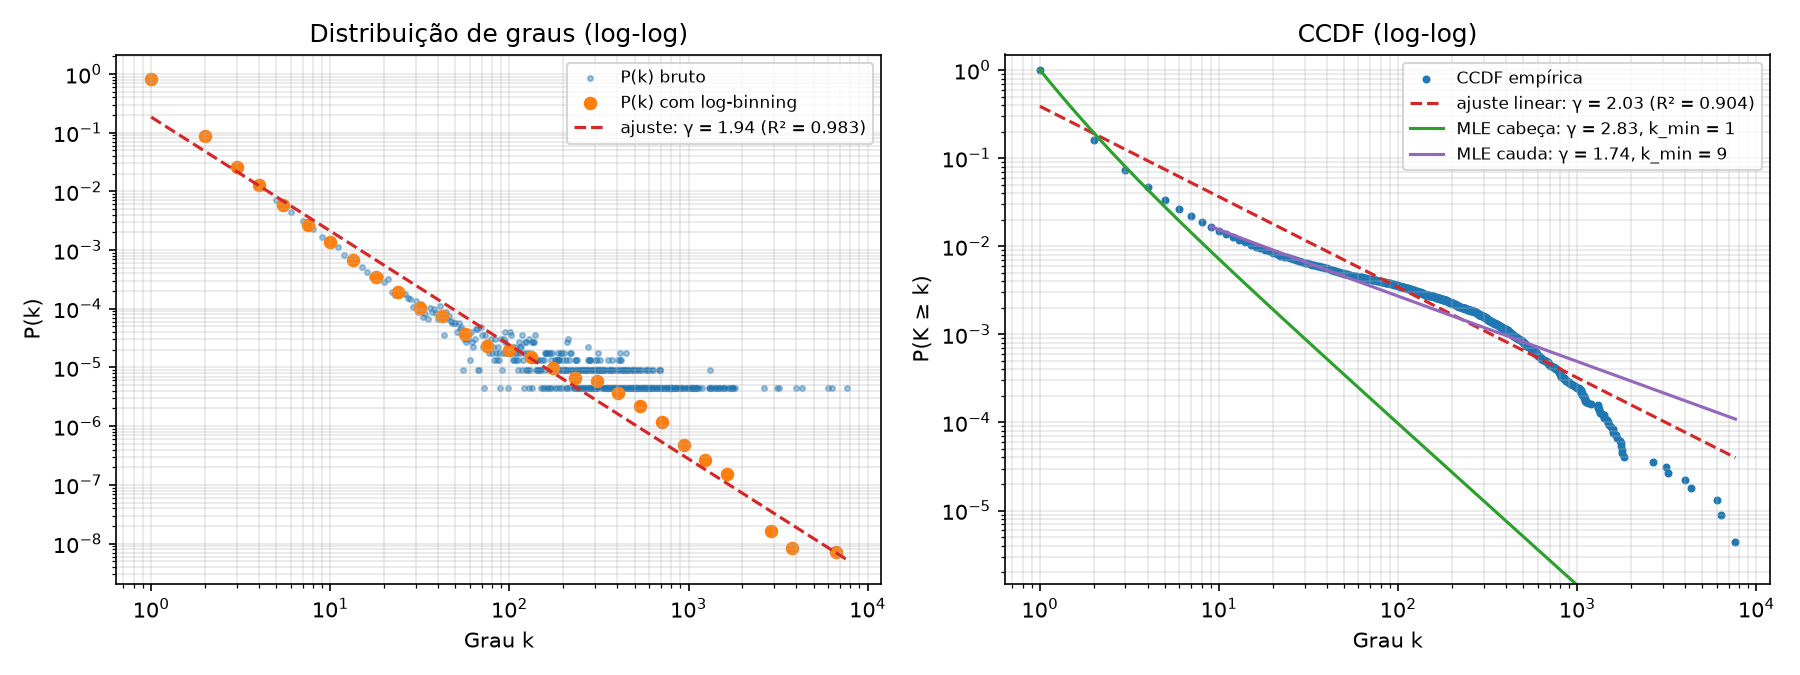

In [11]:
run("powerlaw")
display(table("parte3_powerlaw.csv"))
display(table("parte3_powerlaw_sensibilidade.csv"))
figure("lei_de_potencia.png")

### 4.3 Robustez (remoção de 5% dos vértices)

,metrica,original,aleatoria_media,aleatoria_desvio,direcionada_grau
0,A_fracao_maior_componente,1.000000,0.906546,0.016747,0.000027
1,B_num_componentes,1.000000,9430.633333,3485.933700,213168.000000
2,C_caminho_medio,4.023927,4.123324,0.037587,1.933333
3,D_fracao_isolados,0.000000,0.044066,0.016318,0.996507


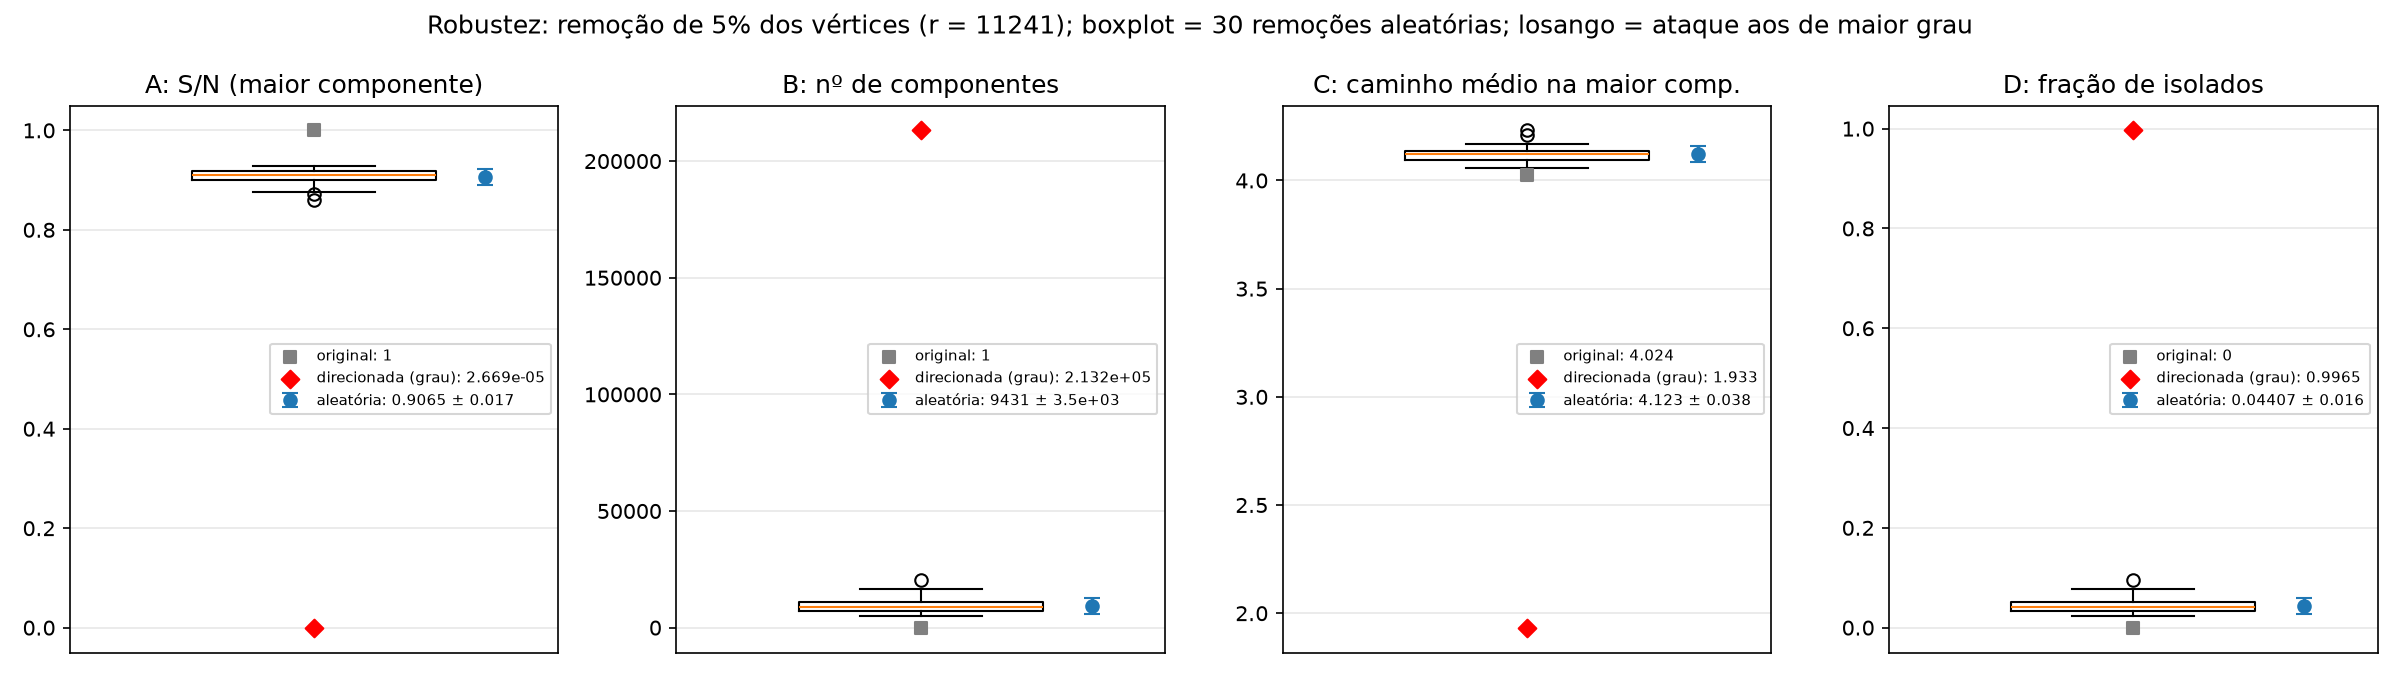

In [12]:
run("robustness")
display(table("parte3_robustez.csv"))
figure("robustez.png")